# Part A: Rebuild nine charts, then take them apart

This notebook reproduces each published recipe, records the self-check, identifies the invited conclusion and decoy, names the mechanism supported by the data, and plots an honest redesign. Every figure uses an explicit `fig, ax = plt.subplots(...)`, declares visual parameters, saves before showing, and reports row filtering or aggregation decisions.

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

DATA = Path.cwd()
if not (DATA / 'case01_helmet_rickshaw.csv').exists():
    DATA = DATA / 'Week 03'

OUTPUT = DATA / 'figures'
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150})
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 3)

def finish(fig, filename):
    fig.tight_layout()
    fig.savefig(OUTPUT / filename, dpi=150, bbox_inches='tight')
    plt.show()

def summary_table(frame, group_col, x_col, y_col):
    rows = []
    for name, group in frame.groupby(group_col, sort=True):
        rows.append({
            'n': len(group),
            'mean_x': group[x_col].mean(),
            'mean_y': group[y_col].mean(),
            'sd_x': group[x_col].std(),
            'sd_y': group[y_col].std(),
            'r': group[x_col].corr(group[y_col]),
            'slope': np.polyfit(group[x_col], group[y_col], 1)[0],
        })
    return pd.DataFrame(rows, index=sorted(frame[group_col].unique())).T

print(f'Data directory: {DATA.resolve()}')
print('Rows removed: none in this notebook. Aggregations are reported where used.')

Data directory: D:\University\ML Lab\Week 03
Rows removed: none in this notebook. Aggregations are reported where used.


## 1. Premium-certified helmets and head injuries

Self-check: {'Premium': 5.4, 'Standard': 2.15}


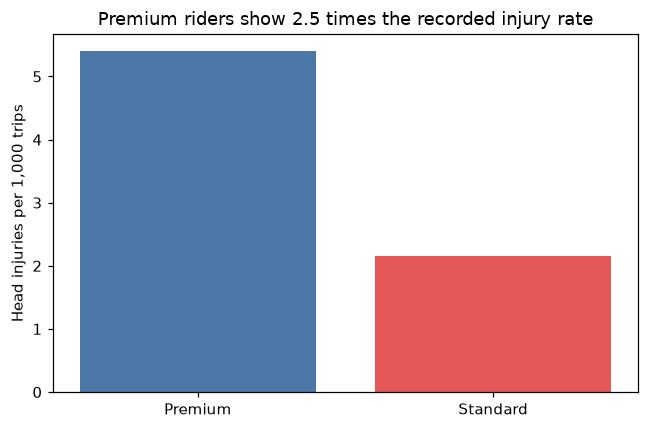


Mechanism check: road-stratified rates per 1,000 trips
helmet_grade      Premium  Standard
road_type                          
City arterial         2.2     3.000
Inner-city lanes      1.0     1.395
Motorway              6.0     8.000
Decoy ruled out: unequal trip totals do not explain the comparison because trips are the denominators.


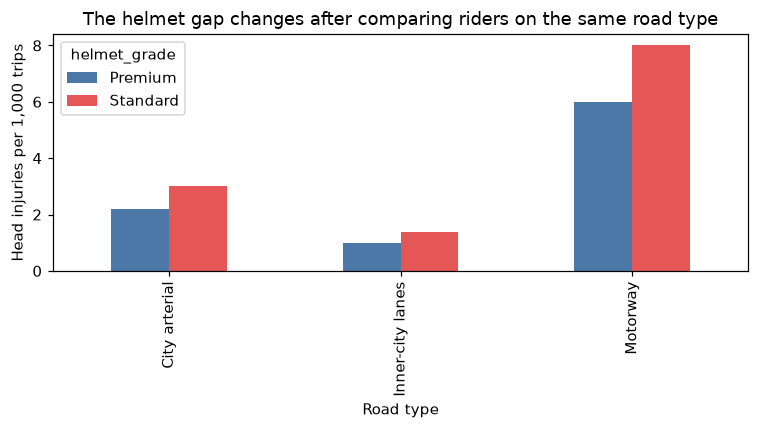

Mechanism: road type is a third variable; the helmet-grade contrast is not constant within road types.


In [15]:
helmet = pd.read_csv(DATA / 'case01_helmet_rickshaw.csv')
helmet_summary = helmet.groupby('helmet_grade', sort=True).agg(
    head_injuries=('head_injuries', 'sum'), trips=('trips', 'sum'), riders=('rider_id', 'size'))
helmet_summary['injuries_per_1000'] = 1000 * helmet_summary['head_injuries'] / helmet_summary['trips']
print('Self-check:', helmet_summary['injuries_per_1000'].round(2).to_dict())
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(helmet_summary.index, helmet_summary['injuries_per_1000'], color=['#4c78a8', '#e45756'])
ax.set_ylim(0, None)
ax.set_ylabel('Head injuries per 1,000 trips')
ax.set_title('Premium riders show 2.5 times the recorded injury rate')
finish(fig, '01_rebuild_helmet.png')

road = helmet.groupby(['road_type', 'helmet_grade']).agg(
    injuries=('head_injuries', 'sum'), trips=('trips', 'sum'))
road['rate_per_1000'] = 1000 * road['injuries'] / road['trips']
print('\nMechanism check: road-stratified rates per 1,000 trips')
print(road['rate_per_1000'].unstack())
print('Decoy ruled out: unequal trip totals do not explain the comparison because trips are the denominators.')
fig, ax = plt.subplots(figsize=(7, 4))
road['rate_per_1000'].unstack().plot(kind='bar', ax=ax, color=['#4c78a8', '#e45756'])
ax.set_ylabel('Head injuries per 1,000 trips')
ax.set_xlabel('Road type')
ax.set_title('The helmet gap changes after comparing riders on the same road type')
finish(fig, '01_redesign_helmet_by_road.png')
print('Mechanism: road type is a third variable; the helmet-grade contrast is not constant within road types.')

## 2. Canteen chai sales and quiz failures

Self-check: Pearson r = 0.982


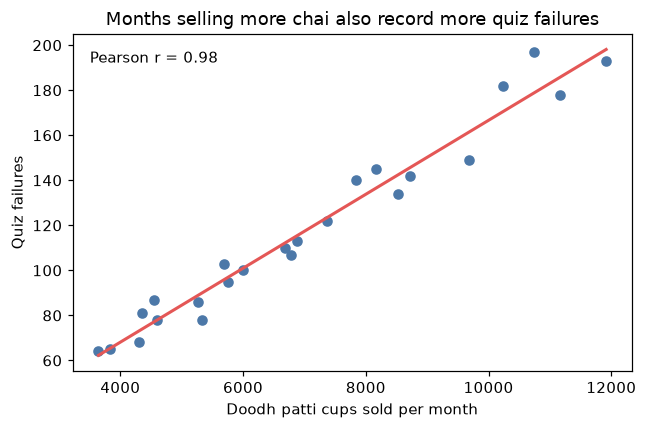

Mechanism check: enrollment vs chai r = 0.997; enrollment vs failures r = 0.977
Decoy ruled out: the pattern is not one anomalous month; all 24 months are plotted.


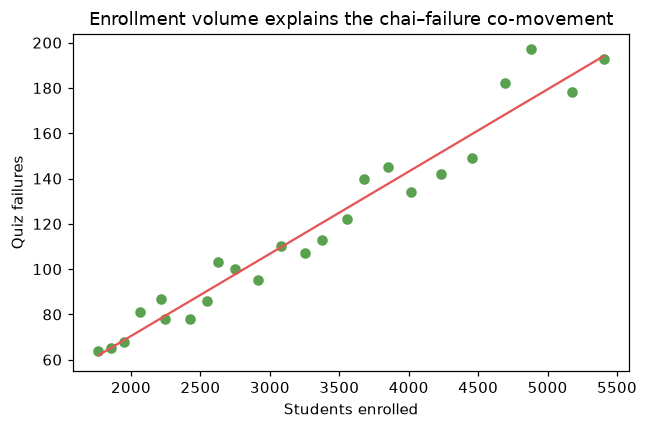

Mechanism: enrollment is a common-volume variable that increases both cups sold and the number of failures.


In [16]:
chai = pd.read_csv(DATA / 'case02_chai_quizzes.csv')
x, y = chai['cups_doodh_patti_sold'], chai['quiz_failures']
slope, intercept = np.polyfit(x, y, 1)
r = x.corr(y)
print(f'Self-check: Pearson r = {r:.3f}')
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, color='#4c78a8', s=35)
grid = np.linspace(x.min(), x.max(), 100)
ax.plot(grid, intercept + slope * grid, color='#e45756', linewidth=2)
ax.text(0.03, 0.95, f'Pearson r = {r:.2f}', transform=ax.transAxes, va='top')
ax.set_xlabel('Doodh patti cups sold per month')
ax.set_ylabel('Quiz failures')
ax.set_title('Months selling more chai also record more quiz failures')
finish(fig, '02_rebuild_chai.png')

enrol_r = chai['students_enrolled'].corr(chai['cups_doodh_patti_sold'])
fail_enrol_r = chai['students_enrolled'].corr(chai['quiz_failures'])
print(f'Mechanism check: enrollment vs chai r = {enrol_r:.3f}; enrollment vs failures r = {fail_enrol_r:.3f}')
print('Decoy ruled out: the pattern is not one anomalous month; all 24 months are plotted.')
sx, sy = chai['students_enrolled'], chai['quiz_failures']
ss, si = np.polyfit(sx, sy, 1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(sx, sy, color='#59a14f', s=35)
ax.plot(np.linspace(sx.min(), sx.max(), 100), si + ss * np.linspace(sx.min(), sx.max(), 100), color='#e45756')
ax.set_xlabel('Students enrolled')
ax.set_ylabel('Quiz failures')
ax.set_title('Enrollment volume explains the chai–failure co-movement')
finish(fig, '02_redesign_enrollment.png')
print('Mechanism: enrollment is a common-volume variable that increases both cups sold and the number of failures.')

## 3. AQI before and after the action-plan marker

Self-check: before = 202, after = 137, fall = 32.1%


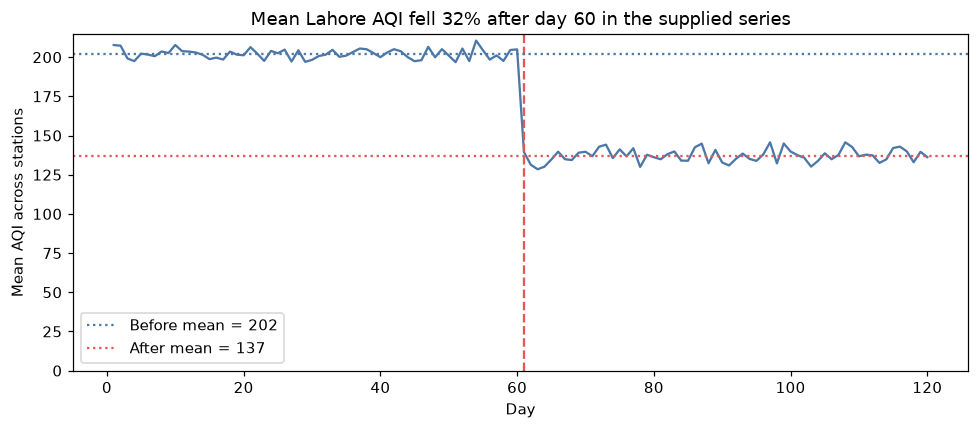

Aggregation rule: 2640 monitor rows become 120 daily means; rows removed = 0.
Mechanism check: zone-specific before/after means
period       After  Before
zone                      
Arterial     245.9   244.7
Industrial     NaN   322.0
Peri-urban    80.4    78.9
Residential  120.8   121.6


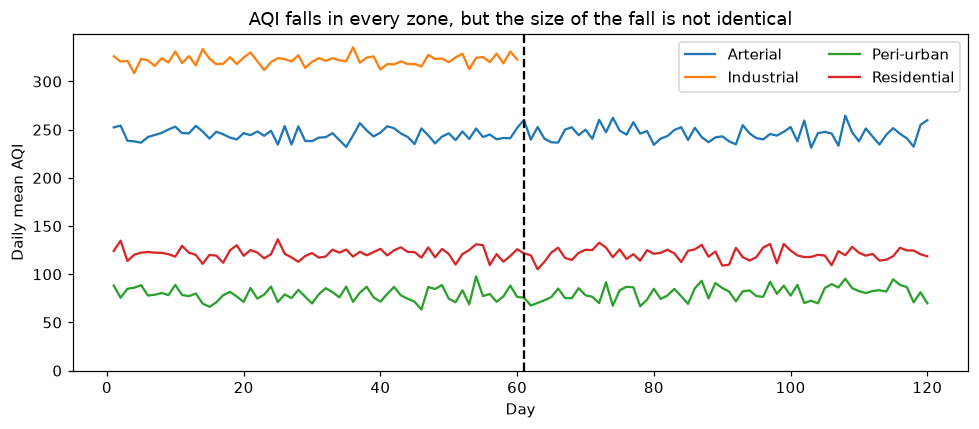

Mechanism: calendar time/season and changing zone coverage are bundled with the day-61 marker; Industrial has no post-marker observations in this file, so the aggregate is not a clean treatment comparison.


In [17]:
aqi = pd.read_csv(DATA / 'case03_aqi_monitors.csv')
daily = aqi.groupby('date', as_index=False)['aqi'].mean()
daily['day'] = np.arange(1, len(daily) + 1)
before = daily.loc[daily['day'] <= 60, 'aqi'].mean()
after = daily.loc[daily['day'] >= 61, 'aqi'].mean()
print(f'Self-check: before = {before:.0f}, after = {after:.0f}, fall = {(before - after) / before:.1%}')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(daily['day'], daily['aqi'], color='#4c78a8')
ax.axvline(61, color='#e45756', linestyle='--', linewidth=1.5)
ax.axhline(before, color='#4c78a8', linestyle=':', label=f'Before mean = {before:.0f}')
ax.axhline(after, color='#e45756', linestyle=':', label=f'After mean = {after:.0f}')
ax.set_ylim(0, None)
ax.set_xlabel('Day')
ax.set_ylabel('Mean AQI across stations')
ax.set_title('Mean Lahore AQI fell 32% after day 60 in the supplied series')
ax.legend()
finish(fig, '03_rebuild_aqi.png')
print(f'Aggregation rule: {len(aqi)} monitor rows become {len(daily)} daily means; rows removed = 0.')

zone_daily = aqi.groupby(['zone', 'date'], as_index=False)['aqi'].mean()
zone_daily['day'] = zone_daily.groupby('zone').cumcount() + 1
zone_means = zone_daily.assign(period=np.where(zone_daily['day'] <= 60, 'Before', 'After')).groupby(['zone', 'period'])['aqi'].mean().unstack()
print('Mechanism check: zone-specific before/after means')
print(zone_means.round(1))
fig, ax = plt.subplots(figsize=(9, 4))
for zone, group in zone_daily.groupby('zone'):
    ax.plot(group['day'], group['aqi'], label=zone)
ax.axvline(61, color='black', linestyle='--')
ax.set_ylim(0, None)
ax.set_xlabel('Day')
ax.set_ylabel('Daily mean AQI')
ax.set_title('AQI falls in every zone, but the size of the fall is not identical')
ax.legend(ncol=2)
finish(fig, '03_redesign_aqi_zones.png')
print('Mechanism: calendar time/season and changing zone coverage are bundled with the day-61 marker; Industrial has no post-marker observations in this file, so the aggregate is not a clean treatment comparison.')

## 4. Department quartet: identical summaries, different geometry

Self-check summary (one column per department):
         Architecture  Business Administration  Computer Science  \
n             11.000                   11.000            11.000   
mean_x        18.000                   18.000            18.000   
mean_y        14.501                   14.501            14.501   
sd_x           6.633                    6.633             6.633   
sd_y           2.031                    2.032             2.032   
r              0.817                    0.816             0.816   
slope          0.250                    0.250             0.250   

        Electrical Engineering  
n                       11.000  
mean_x                  18.000  
mean_y                  14.500  
sd_x                     6.633  
sd_y                     2.030  
r                        0.816  
slope                    0.250  


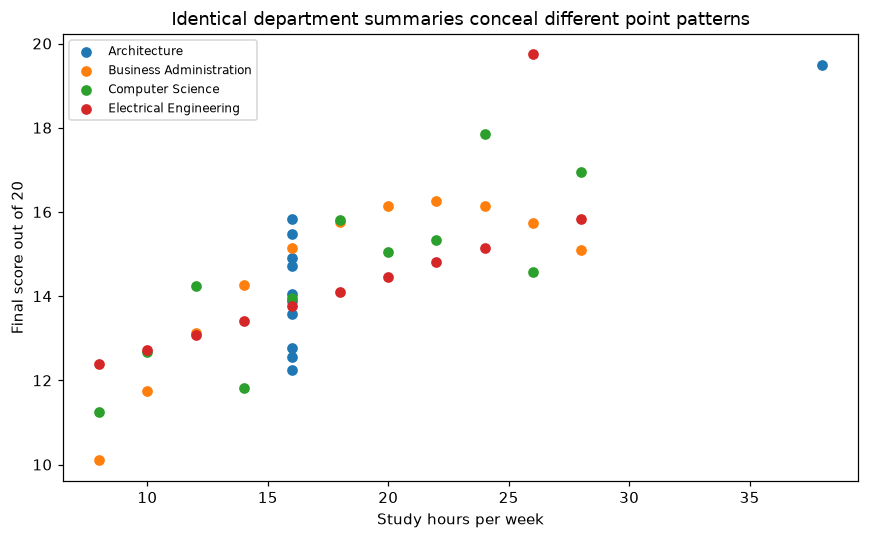

Conclusion invited: fund departments equally because the summary statistics match.
Decoy ruled out: the table is not missing departments; all department rows are included.
Mechanism: leverage, curvature, and outlier placement differ even when means, SDs, r, and slope match.


In [18]:
dept = pd.read_csv(DATA / 'case04_quartet_depts.csv')
dept_summary = summary_table(dept, 'department', 'study_hours_per_week', 'final_score_out_of_20')
print('Self-check summary (one column per department):\n', dept_summary)
fig, ax = plt.subplots(figsize=(8, 5))
for name, group in dept.groupby('department'):
    ax.scatter(group['study_hours_per_week'], group['final_score_out_of_20'], label=name)
ax.set_xlabel('Study hours per week')
ax.set_ylabel('Final score out of 20')
ax.set_title('Identical department summaries conceal different point patterns')
ax.legend(fontsize=8)
finish(fig, '04_department_patterns.png')
print('Conclusion invited: fund departments equally because the summary statistics match.')
print('Decoy ruled out: the table is not missing departments; all department rows are included.')
print('Mechanism: leverage, curvature, and outlier placement differ even when means, SDs, r, and slope match.')

## 5. Same statistics, different shapes

Self-check summary (one column per shape):
            ring     star  straight line  the letter X  two clusters
n       180.000  180.000        180.000       180.000       180.000
mean_x   48.000   48.000         48.000        48.000        48.000
mean_y   63.000   63.000         63.000        63.000        63.000
sd_x     12.033   12.033         12.033        12.033        12.033
sd_y     15.042   15.042         15.042        15.042        15.042
r         0.420    0.420          0.420         0.420         0.420
slope     0.525    0.525          0.525         0.525         0.525


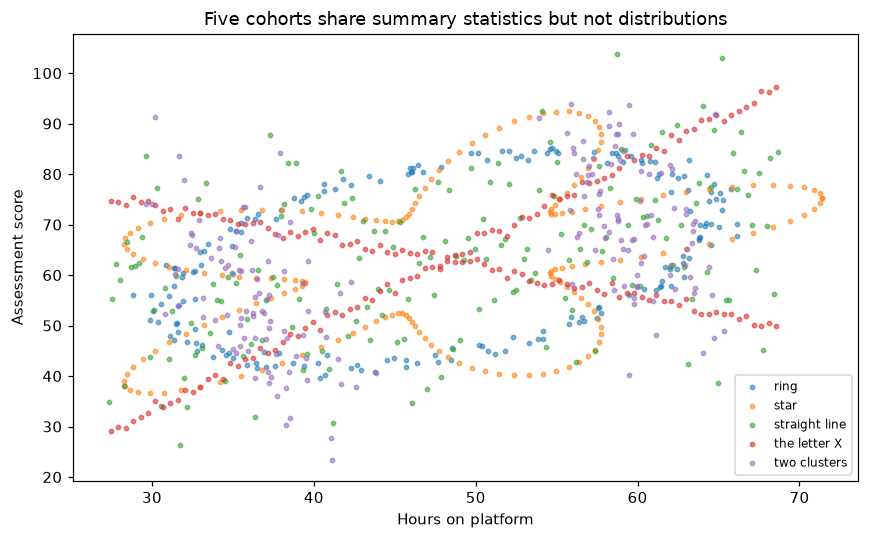

Conclusion invited: one statistical summary describes all five cohorts.
Decoy ruled out: every shape has the same n, means, SDs, correlation, and slope by construction.
Mechanism: clustering, curvature, and outliers change the data geometry while preserving first/second moments.


In [19]:
shapes = pd.read_csv(DATA / 'case05_same_stats_shapes.csv')
shape_summary = summary_table(shapes, 'shape_name', 'hours_on_platform', 'assessment_score')
print('Self-check summary (one column per shape):\n', shape_summary)
fig, ax = plt.subplots(figsize=(8, 5))
for name, group in shapes.groupby('shape_name'):
    ax.scatter(group['hours_on_platform'], group['assessment_score'], s=8, alpha=0.55, label=name)
ax.set_xlabel('Hours on platform')
ax.set_ylabel('Assessment score')
ax.set_title('Five cohorts share summary statistics but not distributions')
ax.legend(fontsize=8)
finish(fig, '05_shape_patterns.png')
print('Conclusion invited: one statistical summary describes all five cohorts.')
print('Decoy ruled out: every shape has the same n, means, SDs, correlation, and slope by construction.')
print('Mechanism: clustering, curvature, and outliers change the data geometry while preserving first/second moments.')

## 6. Sensor correlation matrix

Self-check: matrix = (20, 20); creatinine–HbA1c = 0.77; systolic–MAP = 0.96


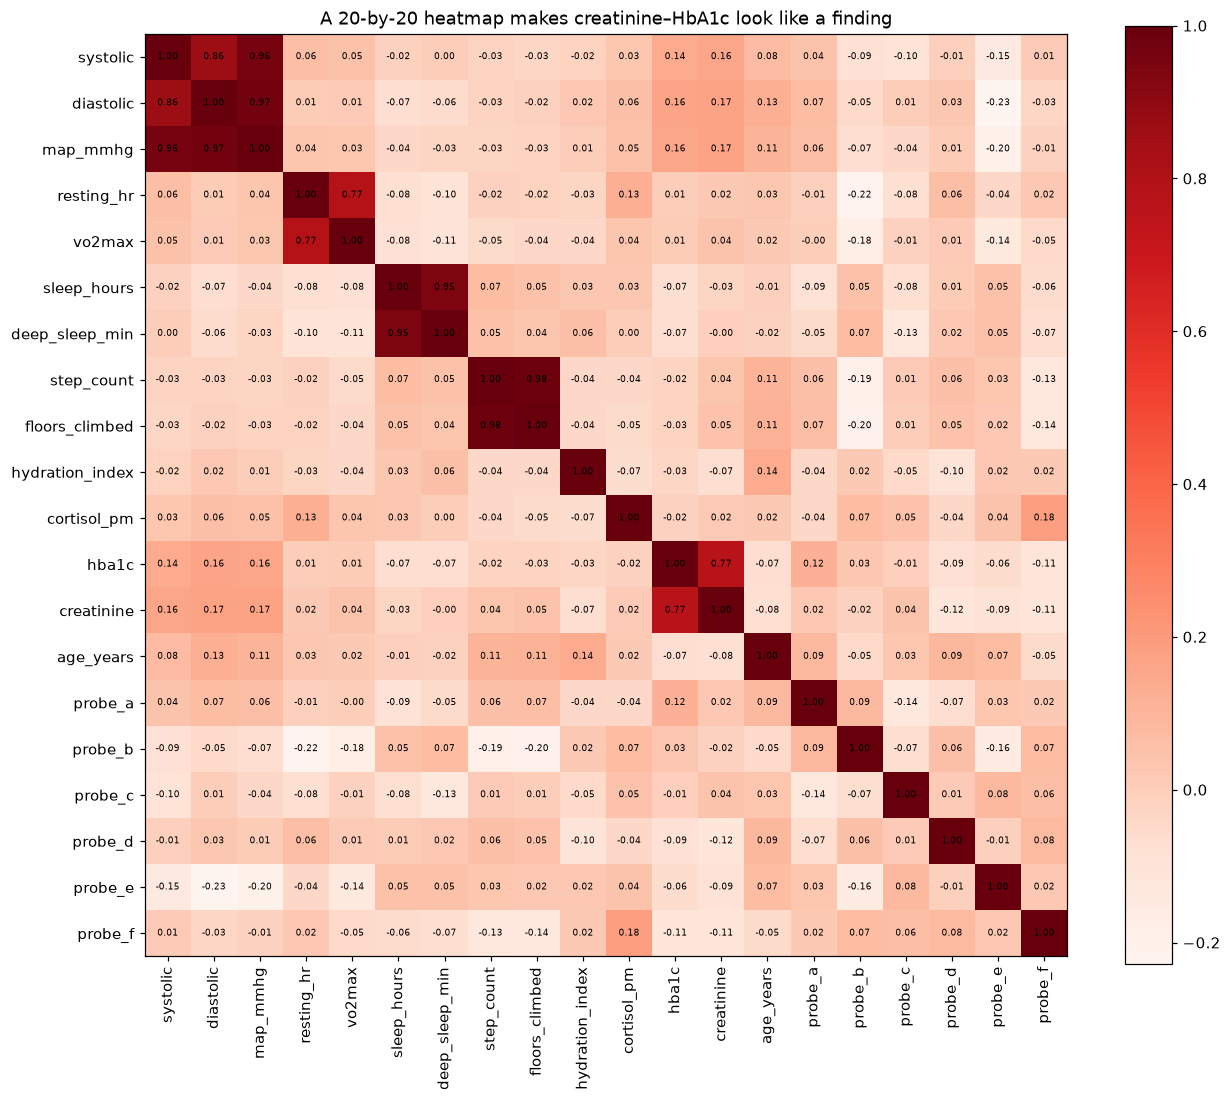

Drawing problem: Reds without fixed vmin/vmax maps the observed range rather than a common correlation scale, and both triangles duplicate each pair.
Meaning problem: correlation is association, not a mechanism; age is a measured candidate confounder.
Age correlations:
creatinine   -0.076
hba1c        -0.068
systolic      0.075
map_mmhg      0.107
Name: age_years, dtype: float64


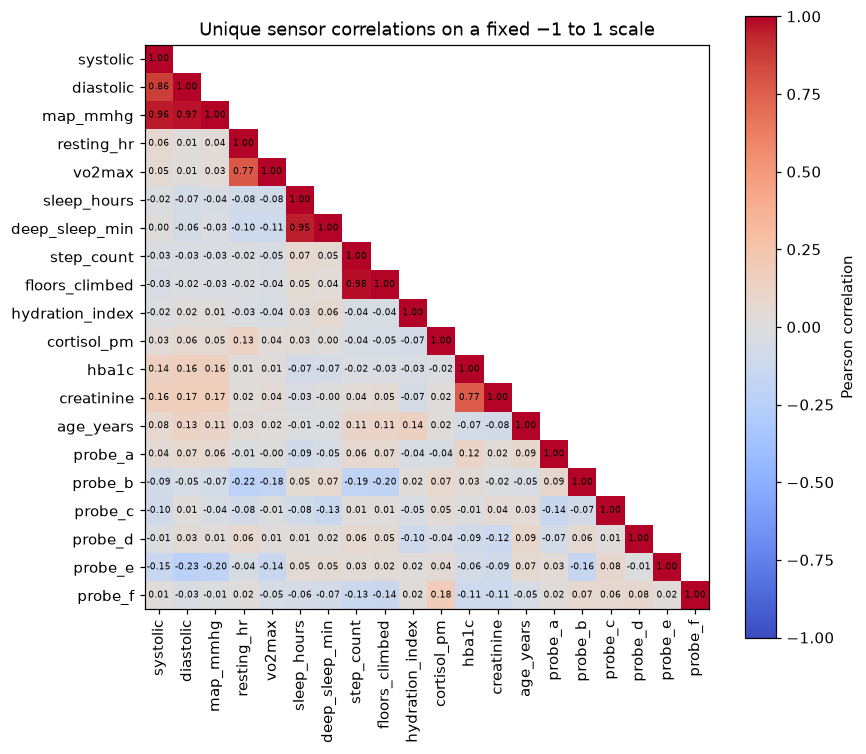

Redesign fixes the drawing; it does not turn the correlations into causal findings.


In [20]:
sensor = pd.read_csv(DATA / 'case06_sensor_matrix.csv')
excluded = ['age_band', 'study_site', 'hr_device_model']
numeric = sensor.drop(columns=excluded).select_dtypes(include='number')
corr = numeric.corr()
print(f'Self-check: matrix = {corr.shape}; creatinine–HbA1c = {corr.loc["creatinine", "hba1c"]:.2f}; systolic–MAP = {corr.loc["systolic", "map_mmhg"]:.2f}')
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap='Reds', vmin=None, vmax=None)
fig.colorbar(im, ax=ax)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=6)
ax.set_title('A 20-by-20 heatmap makes creatinine–HbA1c look like a finding')
finish(fig, '06_rebuild_sensor_heatmap.png')
print('Drawing problem: Reds without fixed vmin/vmax maps the observed range rather than a common correlation scale, and both triangles duplicate each pair.')
print('Meaning problem: correlation is association, not a mechanism; age is a measured candidate confounder.')
print('Age correlations:')
print(corr.loc[['creatinine', 'hba1c', 'systolic', 'map_mmhg'], 'age_years'])
fig, ax = plt.subplots(figsize=(8, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
masked = corr.mask(mask)
im = ax.imshow(masked, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr)):
    for j in range(i + 1):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=6)
ax.set_title('Unique sensor correlations on a fixed −1 to 1 scale')
finish(fig, '06_redesign_sensor_heatmap.png')
print('Redesign fixes the drawing; it does not turn the correlations into causal findings.')

## 7. ShaheenGo revenue and cost: why dual axes mislead

Self-check: cost appears above revenue under the published axis limits: True


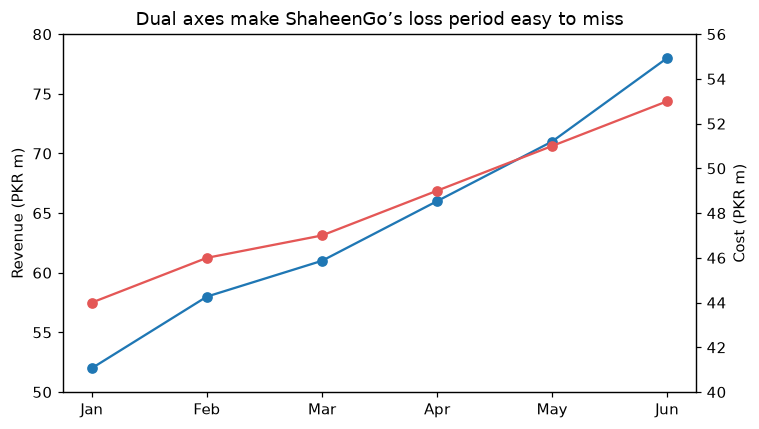

Conclusion invited: the company moved from loss to profit around May.
Decoy ruled out: all months are present; the misleading ordering comes from the unequal axis limits, not missing data.


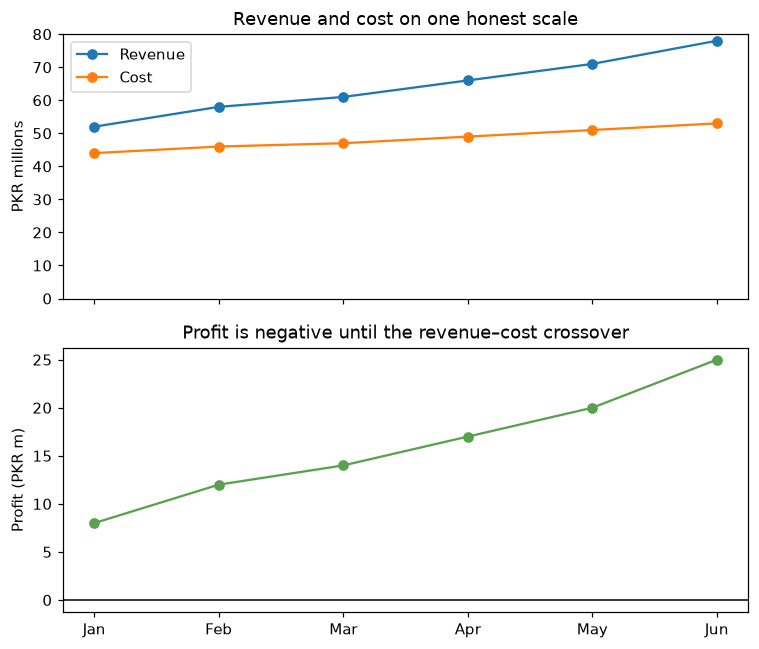

Mechanism: independent y-axis limits change the visual geometry; profit is the common-scale difference between revenue and cost.


In [21]:
series = pd.read_csv(DATA / 'case07_dual_axis_series.csv')
revenue_position = (series.loc[:3, 'revenue_pkr_m'] - 50) / (80 - 50)
cost_position = (series.loc[:3, 'cost_pkr_m'] - 40) / (56 - 40)
print('Self-check: cost appears above revenue under the published axis limits:', bool((cost_position > revenue_position).all()))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(series['month'], series['revenue_pkr_m'], marker='o', label='Revenue (PKR m)')
ax2 = ax.twinx()
ax2.plot(series['month'], series['cost_pkr_m'], marker='o', color='#e45756', label='Cost (PKR m)')
ax.set_ylim(50, 80)
ax2.set_ylim(40, 56)
ax.set_ylabel('Revenue (PKR m)')
ax2.set_ylabel('Cost (PKR m)')
ax.set_title('Dual axes make ShaheenGo’s loss period easy to miss')
finish(fig, '07_rebuild_dual_axis.png')
print('Conclusion invited: the company moved from loss to profit around May.')
print('Decoy ruled out: all months are present; the misleading ordering comes from the unequal axis limits, not missing data.')
series['profit_pkr_m'] = series['revenue_pkr_m'] - series['cost_pkr_m']
fig, ax = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
ax[0].plot(series['month'], series['revenue_pkr_m'], marker='o', label='Revenue')
ax[0].plot(series['month'], series['cost_pkr_m'], marker='o', label='Cost')
ax[0].set_ylim(0, 80)
ax[0].set_ylabel('PKR millions')
ax[0].set_title('Revenue and cost on one honest scale')
ax[0].legend()
ax[1].axhline(0, color='black', linewidth=1)
ax[1].plot(series['month'], series['profit_pkr_m'], marker='o', color='#59a14f')
ax[1].set_ylabel('Profit (PKR m)')
ax[1].set_title('Profit is negative until the revenue–cost crossover')
finish(fig, '07_redesign_revenue_cost_profit.png')
print('Mechanism: independent y-axis limits change the visual geometry; profit is the common-scale difference between revenue and cost.')

## 8. Three histogram bin widths

Rows removed for systolic histograms: 0 because systolic is missing.


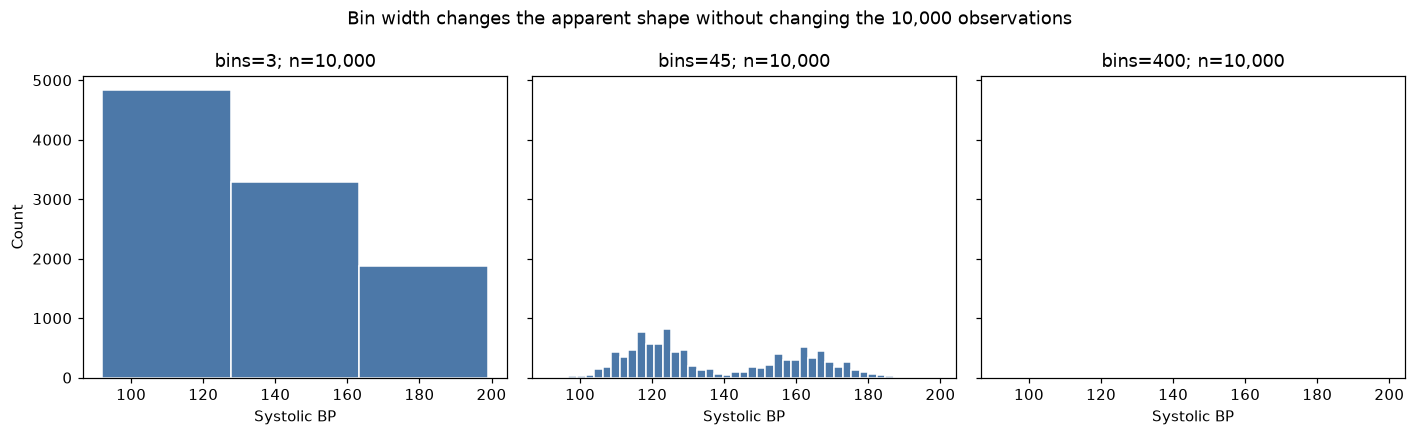

Self-check: n in all three panels = 10000
Conclusion invited: the three panels show three different distributions.
Decoy ruled out: the panels use the same non-missing observations; only the explicit bin count changes.
Mechanism: histogram resolution is a display choice, so broad bins hide structure and narrow bins expose noise.


In [22]:
vitals = pd.read_csv(DATA / 'vitals_10k.csv')
systolic = vitals['systolic'].dropna()
print(f'Rows removed for systolic histograms: {len(vitals) - len(systolic)} because systolic is missing.')
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
bin_choices = [3, 45, 400]
for axis, bin_count in zip(ax, bin_choices):
    axis.hist(systolic, bins=bin_count, color='#4c78a8', edgecolor='white')
    axis.set_title(f'bins={bin_count}; n={len(systolic):,}')
    axis.set_xlabel('Systolic BP')
ax[0].set_ylabel('Count')
fig.suptitle('Bin width changes the apparent shape without changing the 10,000 observations')
finish(fig, '08_rebuild_bin_widths.png')
print('Self-check: n in all three panels =', len(systolic))
print('Conclusion invited: the three panels show three different distributions.')
print('Decoy ruled out: the panels use the same non-missing observations; only the explicit bin count changes.')
print('Mechanism: histogram resolution is a display choice, so broad bins hide structure and narrow bins expose noise.')

## 9. SpO2 KDE beyond the physical maximum

Self-check: maximum observed SpO2 = 100


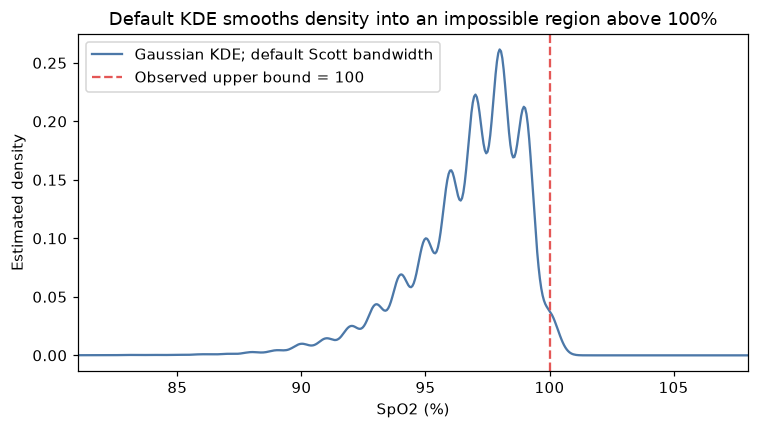

Conclusion invited: 4.4% of the density lies above 100% saturation.
Decoy ruled out: the raw data maximum is exactly 100; no observation exceeds the physical upper bound.
Mechanism: Gaussian KDE has unbounded kernels, so boundary leakage creates density above 100; this is a smoothing artifact, not observed saturation.


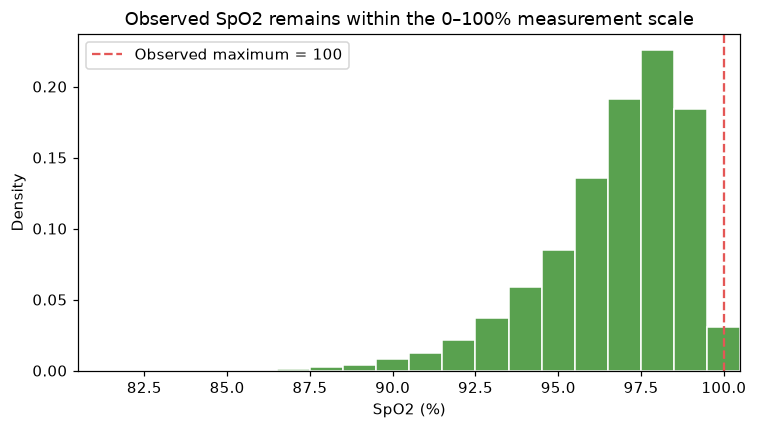

Redesign parameter: integer-width bins from min−0.5 through 100.5; no rows removed beyond missing SpO2 values.


In [23]:
spo2 = vitals['spo2'].dropna()
print(f'Self-check: maximum observed SpO2 = {spo2.max()}')
kde = gaussian_kde(spo2, bw_method='scott')
x_grid = np.linspace(spo2.min(), 108, 500)
density = kde(x_grid)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_grid, density, color='#4c78a8', label='Gaussian KDE; default Scott bandwidth')
ax.axvline(100, color='#e45756', linestyle='--', label='Observed upper bound = 100')
ax.set_xlim(spo2.min(), 108)
ax.set_xlabel('SpO2 (%)')
ax.set_ylabel('Estimated density')
ax.set_title('Default KDE smooths density into an impossible region above 100%')
ax.legend()
finish(fig, '09_rebuild_spo2_kde.png')
print('Conclusion invited: 4.4% of the density lies above 100% saturation.')
print('Decoy ruled out: the raw data maximum is exactly 100; no observation exceeds the physical upper bound.')
print('Mechanism: Gaussian KDE has unbounded kernels, so boundary leakage creates density above 100; this is a smoothing artifact, not observed saturation.')
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(spo2, bins=np.arange(spo2.min() - 0.5, 101.5, 1), density=True, color='#59a14f', edgecolor='white')
ax.axvline(100, color='#e45756', linestyle='--', label='Observed maximum = 100')
ax.set_xlim(spo2.min() - 0.5, 100.5)
ax.set_xlabel('SpO2 (%)')
ax.set_ylabel('Density')
ax.set_title('Observed SpO2 remains within the 0–100% measurement scale')
ax.legend()
finish(fig, '09_redesign_spo2_bounded.png')
print('Redesign parameter: integer-width bins from min−0.5 through 100.5; no rows removed beyond missing SpO2 values.')